# Base de Dados da OBI (`dataset_obi_senior`)


In [9]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path_database = Path("../database/dataset_obi_senior/")
path_results = Path("../results/dataset_obi_senior/")

questions_path = sorted([p for p in path_database.glob("*") if p.is_dir()])
print(f"Total de questões no dataset: {len(questions_path)}")


Total de questões no dataset: 125


In [10]:
problems = []
for q_path in questions_path:
    data = json.loads((q_path / "problem.json").read_text(encoding="utf-8"))
    imgs_dir = q_path / "imgs"
    has_img = imgs_dir.exists() and any(imgs_dir.iterdir())
    data["has_images"] = has_img
    tests_dir = q_path / "tests"
    data["num_tests"] = len(list(tests_dir.glob("*.in"))) if tests_dir.exists() else 0
    problems.append(data)

df_problems = pd.DataFrame(problems)
period_map = {
    "Fase Local": "Fase 1",
    "Fase Nacional": "Fase 3",
    "Fase Estadual": "Fase 2",
    "Fase 2 - Turno B": "Fase 2",
}
df_problems["period"] = df_problems["period"].replace(period_map)
print(df_problems[["title", "year", "period", "level", "has_images", "num_tests"]].head(10))


                      title  year  period   level  has_images  num_tests
0    A idade de Dona Mônica  2019  Fase 1  senior       False          0
1  Acelerador de partículas  2020  Fase 1  senior        True          0
2       Alfabeto Alienígena  2024  Fase 2  senior       False          0
3    Aplicativo de calorias  2020  Fase 3  senior       False          0
4                    Arara!  2025  Fase 2  senior       False          0
5             Arco e flecha  2016  Fase 2  senior        True          0
6               Arranha-céu  2017  Fase 3  senior       False          0
7                   Baralho  2021  Fase 1  senior       False          0
8        Barcos da Nlogônia  2023  Fase 2  senior       False          0
9                    Bingo!  2020  Fase 1  senior        True          0


In [11]:
print("Resumo Geral do Dataset:")
print(f"- Total de questões: {len(df_problems)}")
print(f"- Questões com imagens: {df_problems['has_images'].sum()} ({df_problems['has_images'].mean()*100:.1f}%)")
print(f"- Média de casos de teste por questão: {df_problems['num_tests'].mean():.1f}")
print(f"- Anos: {sorted(df_problems['year'].dropna().unique().tolist())}")
print(f"- Períodos: {df_problems['period'].value_counts().to_dict()}")


Resumo Geral do Dataset:
- Total de questões: 125
- Questões com imagens: 46 (36.8%)
- Média de casos de teste por questão: 0.0
- Anos: ['2016', '2017', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
- Períodos: {'Fase 1': 43, 'Fase 2': 42, 'Fase 3': 40}


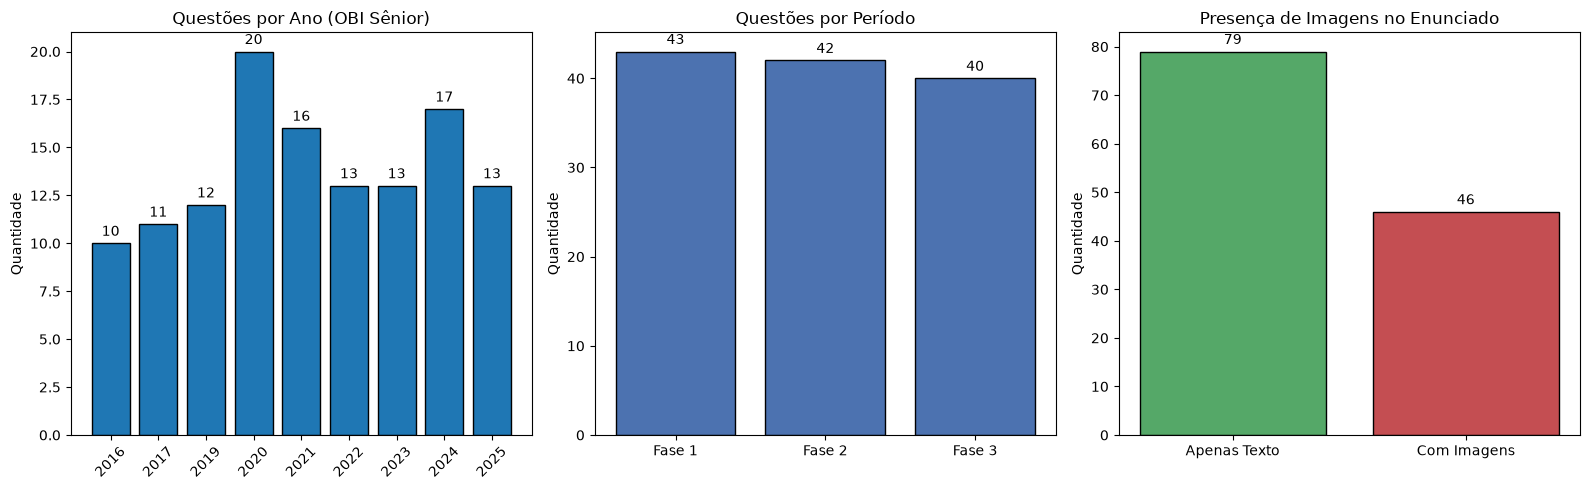

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

year_counts = df_problems["year"].value_counts().sort_index()
bars0 = axes[0].bar(year_counts.index.astype(str), year_counts.values, edgecolor="black")
axes[0].bar_label(bars0, padding=3)
axes[0].set_title("Questões por Ano (OBI Sênior)")
axes[0].set_ylabel("Quantidade")
axes[0].tick_params(axis="x", rotation=45)

period_counts = df_problems["period"].value_counts().sort_index()
bars1 = axes[1].bar(period_counts.index.astype(str), period_counts.values, edgecolor="black", color="#4c72b0")
axes[1].bar_label(bars1, padding=3)
axes[1].set_title("Questões por Período")
axes[1].set_ylabel("Quantidade")

img_counts = df_problems["has_images"].map({True: "Com Imagens", False: "Apenas Texto"}).value_counts()
bars2 = axes[2].bar(img_counts.index, img_counts.values, edgecolor="black", color=["#55a868", "#c44e52"])
axes[2].bar_label(bars2, padding=3)
axes[2].set_title("Presença de Imagens no Enunciado")
axes[2].set_ylabel("Quantidade")

plt.tight_layout()
plt.show()
